# Olist e-commerce: exploratory analysis

Six questions raised by the SQL KPI results (`docs/kpi_results.txt`), each answered with an
independent pandas calculation that is cross-checked against the SQL output.

Source: Olist Brazilian E-Commerce Public Dataset (Kaggle, CC BY-NC-SA 4.0).

Scope: orders that count as sales (not canceled/unavailable), have item rows, and were placed
from 2017-01 to 2018-08 (the complete months). Timestamps are used as recorded; the dataset
does not document their time zone.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3})

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED = ROOT / "data" / "processed"
KPI_DIR = PROCESSED / "kpis"
IMG_DIR = ROOT / "docs" / "images"
IMG_DIR.mkdir(parents=True, exist_ok=True)


def save(fig, name: str) -> None:
    fig.savefig(IMG_DIR / name, dpi=150, bbox_inches="tight")

In [2]:
orders = pd.read_parquet(PROCESSED / "orders.parquet")
items = pd.read_parquet(PROCESSED / "order_items.parquet")
customers = pd.read_parquet(PROCESSED / "customers.parquet")
products = pd.read_parquet(PROCESSED / "products.parquet")
reviews = pd.read_parquet(PROCESSED / "order_reviews.parquet")

sales = orders[
    orders["counts_as_sale"]
    & orders["in_analysis_window"]
    & orders["order_id"].isin(items["order_id"])
]
items_in_sales = items[items["order_id"].isin(sales["order_id"])]
delivered = orders[orders["is_delivered_with_date"] & orders["in_analysis_window"]]

# The notebook must agree with the SQL KPIs.
kpi_monthly = pd.read_csv(KPI_DIR / "monthly_kpis.csv")
assert len(sales) == kpi_monthly["orders"].sum(), "sales orders differ from SQL monthly_kpis"
kpi_delivery = pd.read_csv(KPI_DIR / "delivery_overall.csv")
assert len(delivered) == kpi_delivery["delivered_orders"].iloc[0], "delivered orders differ from SQL"

print(f"sales orders in window: {len(sales):,}")
print(f"delivered orders in window: {len(delivered):,}")

sales orders in window: 97,905
delivered orders in window: 96,203


## 1. Is the November 2017 spike a single day or a sustained shift?

The SQL results show orders up 63% month over month in 2017-11 and down 24% in 2017-12.

Peak day: 2017-11-24 with 1,166 orders = 8.2x the October 2017 median (143 orders/day)


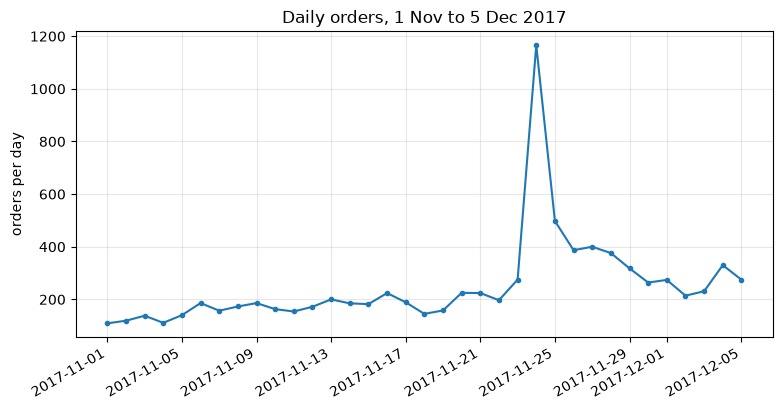

,orders
order_purchase_timestamp,
2017-11-24,1166
2017-11-25,498
2017-11-27,400
2017-11-26,387
2017-11-28,376


In [3]:
daily = sales.groupby(sales["order_purchase_timestamp"].dt.normalize()).size()
window = daily.loc["2017-11-01":"2017-12-05"]
peak_day = daily.loc["2017-10-01":"2017-12-31"].idxmax()
baseline = daily.loc["2017-10-01":"2017-10-31"].median()
print(
    f"Peak day: {peak_day:%Y-%m-%d} with {daily.loc[peak_day]:,} orders "
    f"= {daily.loc[peak_day] / baseline:.1f}x the October 2017 median ({baseline:.0f} orders/day)"
)

fig, ax = plt.subplots()
ax.plot(window.index, window.values, marker="o", markersize=3)
ax.set_title("Daily orders, 1 Nov to 5 Dec 2017")
ax.set_ylabel("orders per day")
fig.autofmt_xdate()
save(fig, "01_daily_orders_nov_2017.png")
plt.show()

daily.nlargest(5).rename("orders").to_frame()

## 2. How much does late delivery hurt review scores?

Delay is measured in calendar days against the estimated delivery date (negative = early).

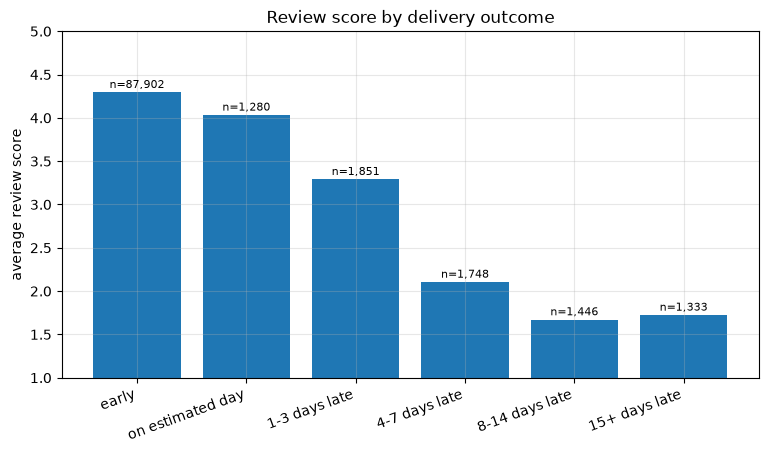

,orders,avg_score,pct_1_star
delay_bucket,,,
early,87902,4.29,6.57
on estimated day,1280,4.03,8.52
1-3 days late,1851,3.29,25.12
4-7 days late,1748,2.10,58.58
8-14 days late,1446,1.67,70.61
15+ days late,1333,1.72,69.02


In [4]:
d = delivered.merge(reviews[["order_id", "review_score"]], on="order_id", how="inner")
kpi_dr = pd.read_csv(KPI_DIR / "delivery_vs_reviews.csv")
assert len(d) == kpi_dr["orders"].sum(), "reviewed delivered orders differ from SQL delivery_vs_reviews"

bins = [-np.inf, -1, 0, 3, 7, 14, np.inf]
labels = ["early", "on estimated day", "1-3 days late", "4-7 days late", "8-14 days late", "15+ days late"]
d["delay_bucket"] = pd.cut(d["delivery_delay_days"], bins=bins, labels=labels)

summary = d.groupby("delay_bucket", observed=True).agg(
    orders=("order_id", "size"),
    avg_score=("review_score", "mean"),
    pct_1_star=("review_score", lambda s: 100 * (s == 1).mean()),
)

fig, ax = plt.subplots()
bars = ax.bar(summary.index.astype(str), summary["avg_score"])
ax.set_ylim(1, 5)
ax.set_ylabel("average review score")
ax.set_title("Review score by delivery outcome")
for bar, n in zip(bars, summary["orders"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.05, f"n={n:,}", ha="center", fontsize=8)
plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
save(fig, "02_delay_vs_review.png")
plt.show()

summary.round(2)

## 3. Are promised delivery dates padded for remote states?

Compares the median actual delivery time with the median promised time (estimated date minus purchase)
for states with at least 100 delivered orders.

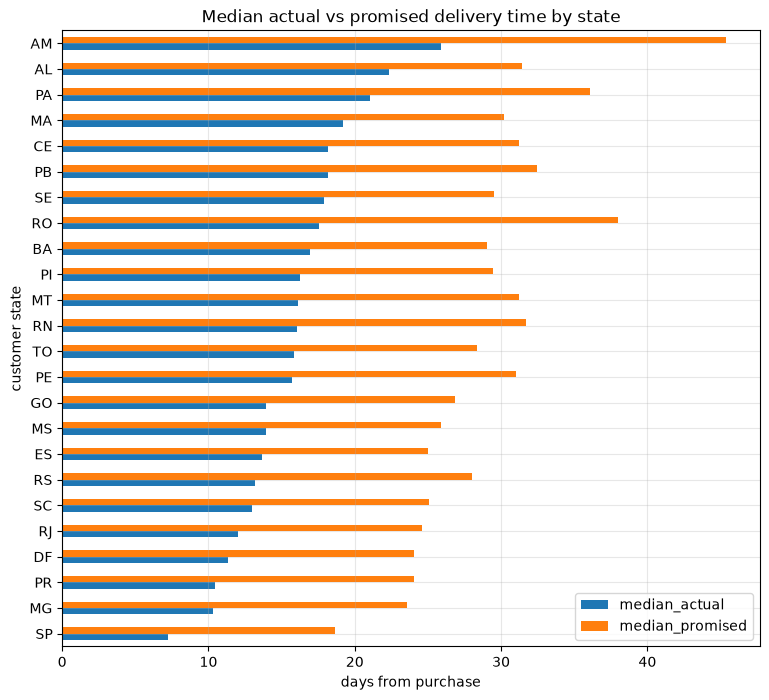

,orders,median_actual,median_promised,late_rate_pct,buffer_days
customer_state,,,,,
AL,396,22.3,31.4,21.5,9.1
MA,713,19.2,30.2,17.5,11.0
ES,1992,13.6,25.0,10.7,11.4
SP,40399,7.2,18.7,4.5,11.5
SE,332,17.9,29.5,15.4,11.6
MS,701,13.9,25.9,9.7,12.0
SC,3537,13.0,25.1,8.2,12.1
BA,3253,16.9,29.0,12.2,12.1
TO,274,15.9,28.4,9.9,12.5


In [5]:
st = delivered.merge(customers[["customer_id", "customer_state"]], on="customer_id")
st["promised_days"] = (
    st["order_estimated_delivery_date"] - st["order_purchase_timestamp"]
).dt.total_seconds() / 86400

by_state = (
    st.groupby("customer_state")
    .agg(
        orders=("order_id", "size"),
        median_actual=("delivery_days", "median"),
        median_promised=("promised_days", "median"),
        late_rate_pct=("delivery_delay_days", lambda s: 100 * (s > 0).mean()),
    )
    .query("orders >= 100")
)
by_state["buffer_days"] = by_state["median_promised"] - by_state["median_actual"]

kpi_states = pd.read_csv(KPI_DIR / "delivery_by_state.csv")
assert set(by_state.index) == set(kpi_states["customer_state"]), "state list differs from SQL delivery_by_state"

ax = by_state.sort_values("median_actual")[["median_actual", "median_promised"]].plot.barh(figsize=(9, 8))
ax.set_xlabel("days from purchase")
ax.set_ylabel("customer state")
ax.set_title("Median actual vs promised delivery time by state")
save(ax.figure, "03_promised_vs_actual_by_state.png")
plt.show()

by_state.sort_values("buffer_days").round(1)

## 4. How concentrated is seller revenue?

Sellers are ranked by revenue; the curve shows the cumulative share of total revenue.

3,029 active sellers | top 10 sellers: 13.2% | top 302 sellers (10%): 67.3%


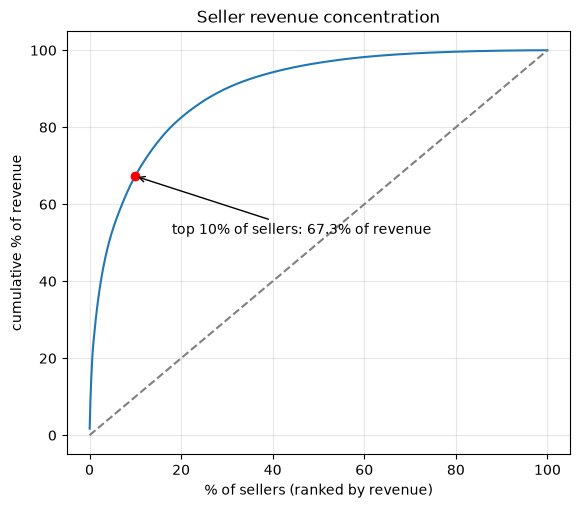

In [6]:
rev = items_in_sales.groupby("seller_id")["price"].sum().sort_values(ascending=False)
n = len(rev)
k = n // 10
top10_share = 100 * rev.iloc[:10].sum() / rev.sum()
top_decile_share = 100 * rev.iloc[:k].sum() / rev.sum()

kpi_sc = pd.read_csv(KPI_DIR / "seller_concentration.csv").iloc[0]
assert n == kpi_sc["active_sellers"], "active sellers differ from SQL"
assert abs(top10_share - kpi_sc["top10_sellers_share_pct"]) < 0.1, "top-10 share differs from SQL"
assert abs(top_decile_share - kpi_sc["top_decile_sellers_share_pct"]) < 0.1, "top-decile share differs from SQL"
print(f"{n:,} active sellers | top 10 sellers: {top10_share:.1f}% | top {k} sellers (10%): {top_decile_share:.1f}%")

x = np.arange(1, n + 1) / n * 100
y = rev.cumsum().to_numpy() / rev.sum() * 100

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.plot(x, y)
ax.plot([0, 100], [0, 100], linestyle="--", color="grey")
ax.scatter([k / n * 100], [top_decile_share], color="red", zorder=3)
ax.annotate(
    f"top 10% of sellers: {top_decile_share:.1f}% of revenue",
    (k / n * 100, top_decile_share),
    xytext=(18, top_decile_share - 15),
    arrowprops={"arrowstyle": "->"},
)
ax.set_xlabel("% of sellers (ranked by revenue)")
ax.set_ylabel("cumulative % of revenue")
ax.set_title("Seller revenue concentration")
save(fig, "04_seller_concentration.png")
plt.show()

## 5. Which big categories have unhappy customers?

Categories with at least 300 orders. Bubble size is revenue. Review scores are averaged over item
rows (an order with several items counts once per item), as defined in `docs/kpi_definitions.md`.

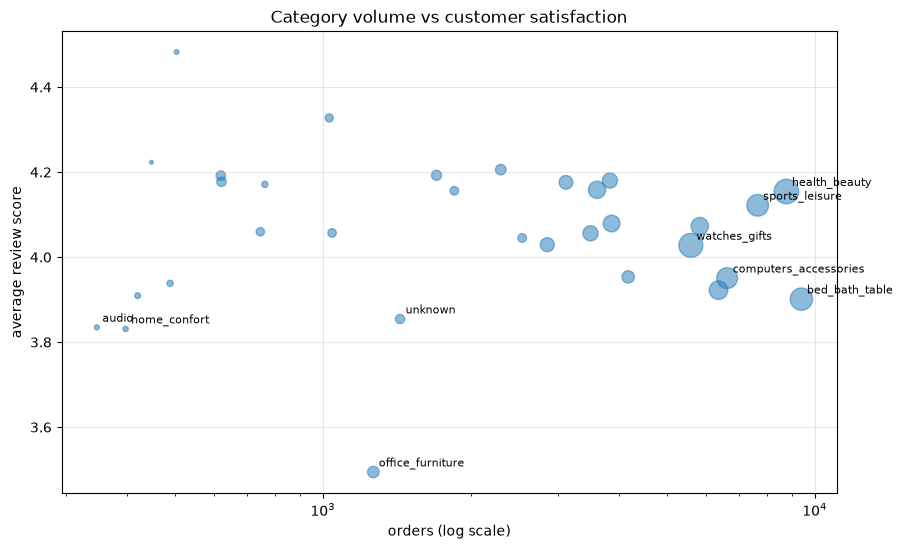

,orders,revenue,avg_score
category,,,
office_furniture,1266,272279.82,3.49
home_confort,397,58572.04,3.83
audio,347,50511.61,3.83
unknown,1435,178506.66,3.85
bed_bath_table,9394,1035485.07,3.90
furniture_living_room,420,68638.56,3.91
furniture_decor,6373,721584.27,3.92
home_construction,489,83010.12,3.94
computers_accessories,6636,902922.70,3.95


In [7]:
items_cat = (
    items_in_sales.merge(
        products[["product_id", "product_category_name_english"]], on="product_id", how="left"
    )
    .merge(reviews[["order_id", "review_score"]], on="order_id", how="left")
    .rename(columns={"product_category_name_english": "category"})
)

cat_all = items_cat.groupby("category").agg(
    orders=("order_id", "nunique"),
    revenue=("price", "sum"),
    avg_score=("review_score", "mean"),
)

kpi_cat = pd.read_csv(KPI_DIR / "category_performance.csv").iloc[0]
assert abs(cat_all.loc[kpi_cat["category"], "revenue"] - kpi_cat["revenue"]) < 0.01, "top category revenue differs from SQL"

cat = cat_all.query("orders >= 300")
highlight = set(cat.nlargest(5, "revenue").index) | set(cat.nsmallest(5, "avg_score").index)

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(cat["orders"], cat["avg_score"], s=cat["revenue"] / 4000, alpha=0.5)
ax.set_xscale("log")
for name in highlight:
    ax.annotate(
        name, (cat.loc[name, "orders"], cat.loc[name, "avg_score"]),
        fontsize=8, xytext=(4, 4), textcoords="offset points",
    )
ax.set_xlabel("orders (log scale)")
ax.set_ylabel("average review score")
ax.set_title("Category volume vs customer satisfaction")
save(fig, "05_category_volume_vs_rating.png")
plt.show()

cat.sort_values("avg_score").head(10).round(2)

## 6. When do customers order?

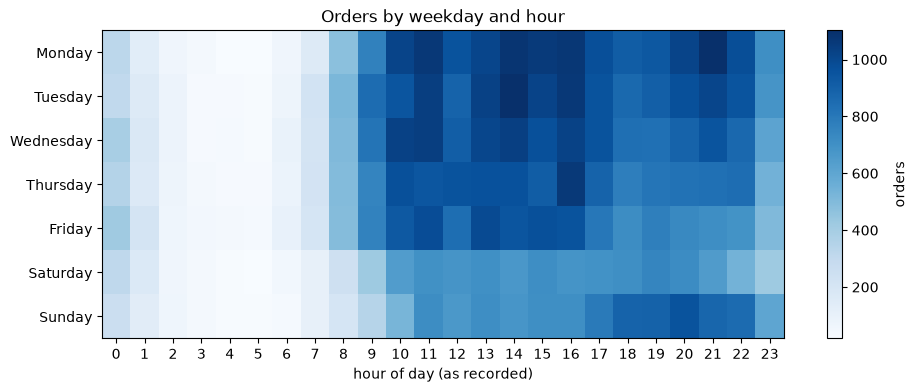

share of orders by weekday (%):
weekday
Monday       16.3
Tuesday      16.0
Wednesday    15.6
Thursday     14.8
Friday       14.2
Saturday     11.0
Sunday       12.1

busiest 3 hours (orders):
hour
16    6575
11    6477
14    6474


In [8]:
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
t = sales["order_purchase_timestamp"]
heat = (
    pd.DataFrame({"weekday": t.dt.day_name(), "hour": t.dt.hour})
    .groupby(["weekday", "hour"])
    .size()
    .unstack(fill_value=0)
    .reindex(index=days, columns=range(24), fill_value=0)
)

fig, ax = plt.subplots(figsize=(11, 4))
im = ax.imshow(heat.values, aspect="auto", cmap="Blues")
ax.grid(False)
ax.set_yticks(range(7), labels=days)
ax.set_xticks(range(24), labels=[str(h) for h in range(24)])
ax.set_xlabel("hour of day (as recorded)")
ax.set_title("Orders by weekday and hour")
fig.colorbar(im, ax=ax, label="orders")
save(fig, "06_orders_by_weekday_hour.png")
plt.show()

print("share of orders by weekday (%):")
print((heat.sum(axis=1) / heat.values.sum() * 100).round(1).to_string())
print("\nbusiest 3 hours (orders):")
print(heat.sum(axis=0).sort_values(ascending=False).head(3).to_string())